> For direct ensemble training, validation and submission generation, open
> [PIPELINE_WORKFLOW.ipynb](PIPELINE_WORKFLOW.ipynb). This notebook retains the
> earlier analysis. Historical prose/results are not newly measured scores.


In [1]:
from pathlib import Path
import os, sys
import numpy as np
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "run.py").exists() and (p / "preprocessing.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the extracted project folder.")
sys.path.insert(0, str(ROOT))
# Legacy notebooks use ../ paths, so give every notebook the same working directory.
os.chdir(ROOT / "notebooks")
print("Project:", ROOT)


Project: /Users/chenguanyu/Desktop/Machine Learning/proj.1/ML_Project1-zhihao 4


# 02 — Experiments: Baselines, Cross-Validation & Ablation

**EPFL CS-433 Machine Learning (Fall 2026) — Project 1**

**Objective:** Run leak-free 5-fold stratified cross-validation on candidate models, demonstrate the impact of decision threshold calibration on class-imbalanced metrics, and produce empirical figures for the scientific report.

**Author:** Zhihao Chen

In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")  # import project modules from repo root

import os
import time
import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission
import implementations as impl
import preprocessing as prep
import metrics
import cross_validation as cv

DATA_PATH = "../data/dataset"
SEED = 42
np.random.seed(SEED)

print("Environment initialized.")

Environment initialized.


## 1. Load and clean the data
The notebook is self-contained: it loads the supplied CSVs through the shared
cache, applies the clean-track feature rules, and fits imputation/scaling inside
each fold. The default reproducible 10,000-row sample keeps Run All manageable.
Set `N_ROWS=None` for all rows. Sample results are not full-data report results.


In [3]:
N_ROWS = 10_000  # None for the full dataset; random sample, not the first rows
K_FOLDS = 5
MAX_ITERS = 300
x_raw, _, y_raw, _, _ = prep.load_data_cached(DATA_PATH)
feature_names = prep.load_feature_names(DATA_PATH)
selected = np.arange(len(y_raw)) if N_ROWS is None else np.sort(
    np.random.default_rng(SEED).choice(len(y_raw), min(N_ROWS, len(y_raw)), replace=False))
x_train, clean_names = prep.clean_data(x_raw[selected], feature_names)
y_train = y_raw[selected]
del x_raw, y_raw
(ROOT / "report/figures").mkdir(parents=True, exist_ok=True)
print(f"Evaluation rows: {len(y_train):,}; clean features: {x_train.shape[1]}; folds: {K_FOLDS}")


Evaluation rows: 10,000; clean features: 157; folds: 5


## 2. Sanity Check of `implementations.py`
We verify that gradient descent minimizes loss and test equivalence of least squares and ridge with $\lambda=0$.

In [4]:
# Use a controlled full-rank design to illustrate least-squares equivalence.
rng = np.random.default_rng(SEED)
tx_small = np.c_[np.ones(1000), rng.normal(size=(1000, 5))]
y_small = tx_small @ np.arange(6) + rng.normal(size=1000)
w_gd, loss_gd = impl.mean_squared_error_gd(y_small, tx_small, np.zeros(6), max_iters=100, gamma=0.1)
w_ls, loss_ls = impl.least_squares(y_small, tx_small)
w_ridge0, loss_ridge0 = impl.ridge_regression(y_small, tx_small, lambda_=0.0)
assert np.allclose(w_ls, w_ridge0)
print(f"Synthetic illustration: GD MSE {loss_gd:.4f}; LS MSE {loss_ls:.4f}")


Synthetic illustration: GD MSE 0.5181; LS MSE 0.5181


## 3. Baselines: 5-Fold Stratified Cross-Validation
We run leak-free 5-fold cross-validation on:
- **B0**: Majority Class Dummy (all -1)
- **B1a**: Ridge Regression ($\lambda=10^{-4}$, default $\tau=0.0$)
- **B1b**: Ridge Regression ($\lambda=10^{-4}$, calibrated $\tau^*$)
- **B2a**: Regularized Logistic Regression ($\lambda=10^{-4}$, default $\tau=0.5$)
- **B2b**: Regularized Logistic Regression ($\lambda=10^{-4}$, calibrated $\tau^*$)

In [5]:
# Fit each learner once per fold; compare two thresholds on the same scores.
# The existing cross_validate API always tunes a threshold, so this explicit loop
# also supports fixed-threshold baselines without passing obsolete arguments.
k_indices = cv.build_k_indices(y_train, k_fold=K_FOLDS, seed=SEED)
records = {name: [] for name in ["dummy", "ridge_default", "ridge_tuned",
                               "logistic_default", "logistic_tuned"]}
oof = {name: np.empty(len(y_train), dtype=int) for name in records}
for k in range(K_FOLDS):
    tr, va = cv.fold_split(k_indices, k)
    tx_tr, tx_va = cv.preprocess_fold(x_train[tr], x_train[va])
    wr, _ = impl.ridge_regression(y_train[tr].astype(float), tx_tr, lambda_=1e-4)
    wl, _ = impl.reg_logistic_regression((y_train[tr] == 1).astype(float), tx_tr,
        lambda_=1e-4, initial_w=np.zeros(tx_tr.shape[1]), max_iters=MAX_ITERS, gamma=0.1)
    rtr, rva = tx_tr @ wr, tx_va @ wr
    ltr, lva = impl.sigmoid(tx_tr @ wl), impl.sigmoid(tx_va @ wl)
    rt, _ = metrics.best_threshold(y_train[tr], rtr)
    lt, _ = metrics.best_threshold(y_train[tr], ltr)
    predictions = {"dummy": np.full(len(va), -1),
        "ridge_default": metrics.predict_labels(rva, 0),
        "ridge_tuned": metrics.predict_labels(rva, rt),
        "logistic_default": metrics.predict_labels(lva, .5),
        "logistic_tuned": metrics.predict_labels(lva, lt)}
    for name, pred in predictions.items():
        precision, recall, f1 = metrics.precision_recall_f1(y_train[va], pred)
        records[name].append(dict(accuracy=metrics.accuracy(y_train[va], pred),
            precision=precision, recall=recall, f1=f1,
            balanced_accuracy=metrics.confusion_matrix(y_train[va], pred)['balanced_accuracy']))
        oof[name][va] = pred
    if k == 0:
        probs_val, y_val_f0, training_threshold = lva, y_train[va], lt
    print(f"Completed fold {k+1}/{K_FOLDS}", flush=True)

def summarize_rows(rows):
    return {key + suffix: float(fn([row[key] for row in rows]))
            for key in rows[0] for suffix, fn in [("_mean", np.mean), ("_std", np.std)]}
res_b0, res_b1a, res_b1b, res_b2a, res_b2b = [summarize_rows(records[name]) for name in records]


Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


In [6]:
# Display Table 1: Baseline Comparison Table
print("=" * 94)
print(f"{'Model / Baseline':<32} | {'Val Acc':<8} | {'Precision':<10} | {'Recall':<8} | {'Balanced Acc':<12} | {'Val F1 (+1)':<12}")
print("-" * 94)
print(f"{'B0: All-Negative Dummy':<32} | {res_b0['accuracy_mean']:.4f}   | {res_b0['precision_mean']:.4f}     | {res_b0['recall_mean']:.4f}   | {res_b0['balanced_accuracy_mean']:.4f}       | {res_b0['f1_mean']:.4f}")
print(f"{'B1a: Ridge (tau=0.0)':<32} | {res_b1a['accuracy_mean']:.4f}   | {res_b1a['precision_mean']:.4f}     | {res_b1a['recall_mean']:.4f}   | {res_b1a['balanced_accuracy_mean']:.4f}       | {res_b1a['f1_mean']:.4f} +/- {res_b1a['f1_std']:.4f}")
print(f"{'B1b: Ridge (Tuned tau)':<32} | {res_b1b['accuracy_mean']:.4f}   | {res_b1b['precision_mean']:.4f}     | {res_b1b['recall_mean']:.4f}   | {res_b1b['balanced_accuracy_mean']:.4f}       | {res_b1b['f1_mean']:.4f} +/- {res_b1b['f1_std']:.4f}")
print(f"{'B2a: Logistic (tau=0.5)':<32} | {res_b2a['accuracy_mean']:.4f}   | {res_b2a['precision_mean']:.4f}     | {res_b2a['recall_mean']:.4f}   | {res_b2a['balanced_accuracy_mean']:.4f}       | {res_b2a['f1_mean']:.4f} +/- {res_b2a['f1_std']:.4f}")
print(f"{'B2b: Logistic (Tuned tau)':<32} | {res_b2b['accuracy_mean']:.4f}   | {res_b2b['precision_mean']:.4f}     | {res_b2b['recall_mean']:.4f}   | {res_b2b['balanced_accuracy_mean']:.4f}       | {res_b2b['f1_mean']:.4f} +/- {res_b2b['f1_std']:.4f}")
print("=" * 94)

Model / Baseline                 | Val Acc  | Precision  | Recall   | Balanced Acc | Val F1 (+1) 
----------------------------------------------------------------------------------------------
B0: All-Negative Dummy           | 0.9078   | 0.0000     | 0.0000   | 0.5000       | 0.0000
B1a: Ridge (tau=0.0)             | 0.9102   | 0.5982     | 0.0791   | 0.5369       | 0.1396 +/- 0.0274
B1b: Ridge (Tuned tau)           | 0.8621   | 0.3420     | 0.5260   | 0.7111       | 0.4127 +/- 0.0192
B2a: Logistic (tau=0.5)          | 0.9094   | 0.5264     | 0.1605   | 0.5730       | 0.2454 +/- 0.0344
B2b: Logistic (Tuned tau)        | 0.8662   | 0.3533     | 0.5175   | 0.7096       | 0.4151 +/- 0.0193


## 4. Understand the precision–recall trade-off
This validation curve is exploratory. Its peak uses validation labels and is
**not an unbiased score**. The CV table above instead selects thresholds on
training-fold scores and evaluates them on unseen fold rows. Training-score
calibration itself can overfit; nested calibration is a stronger future protocol.


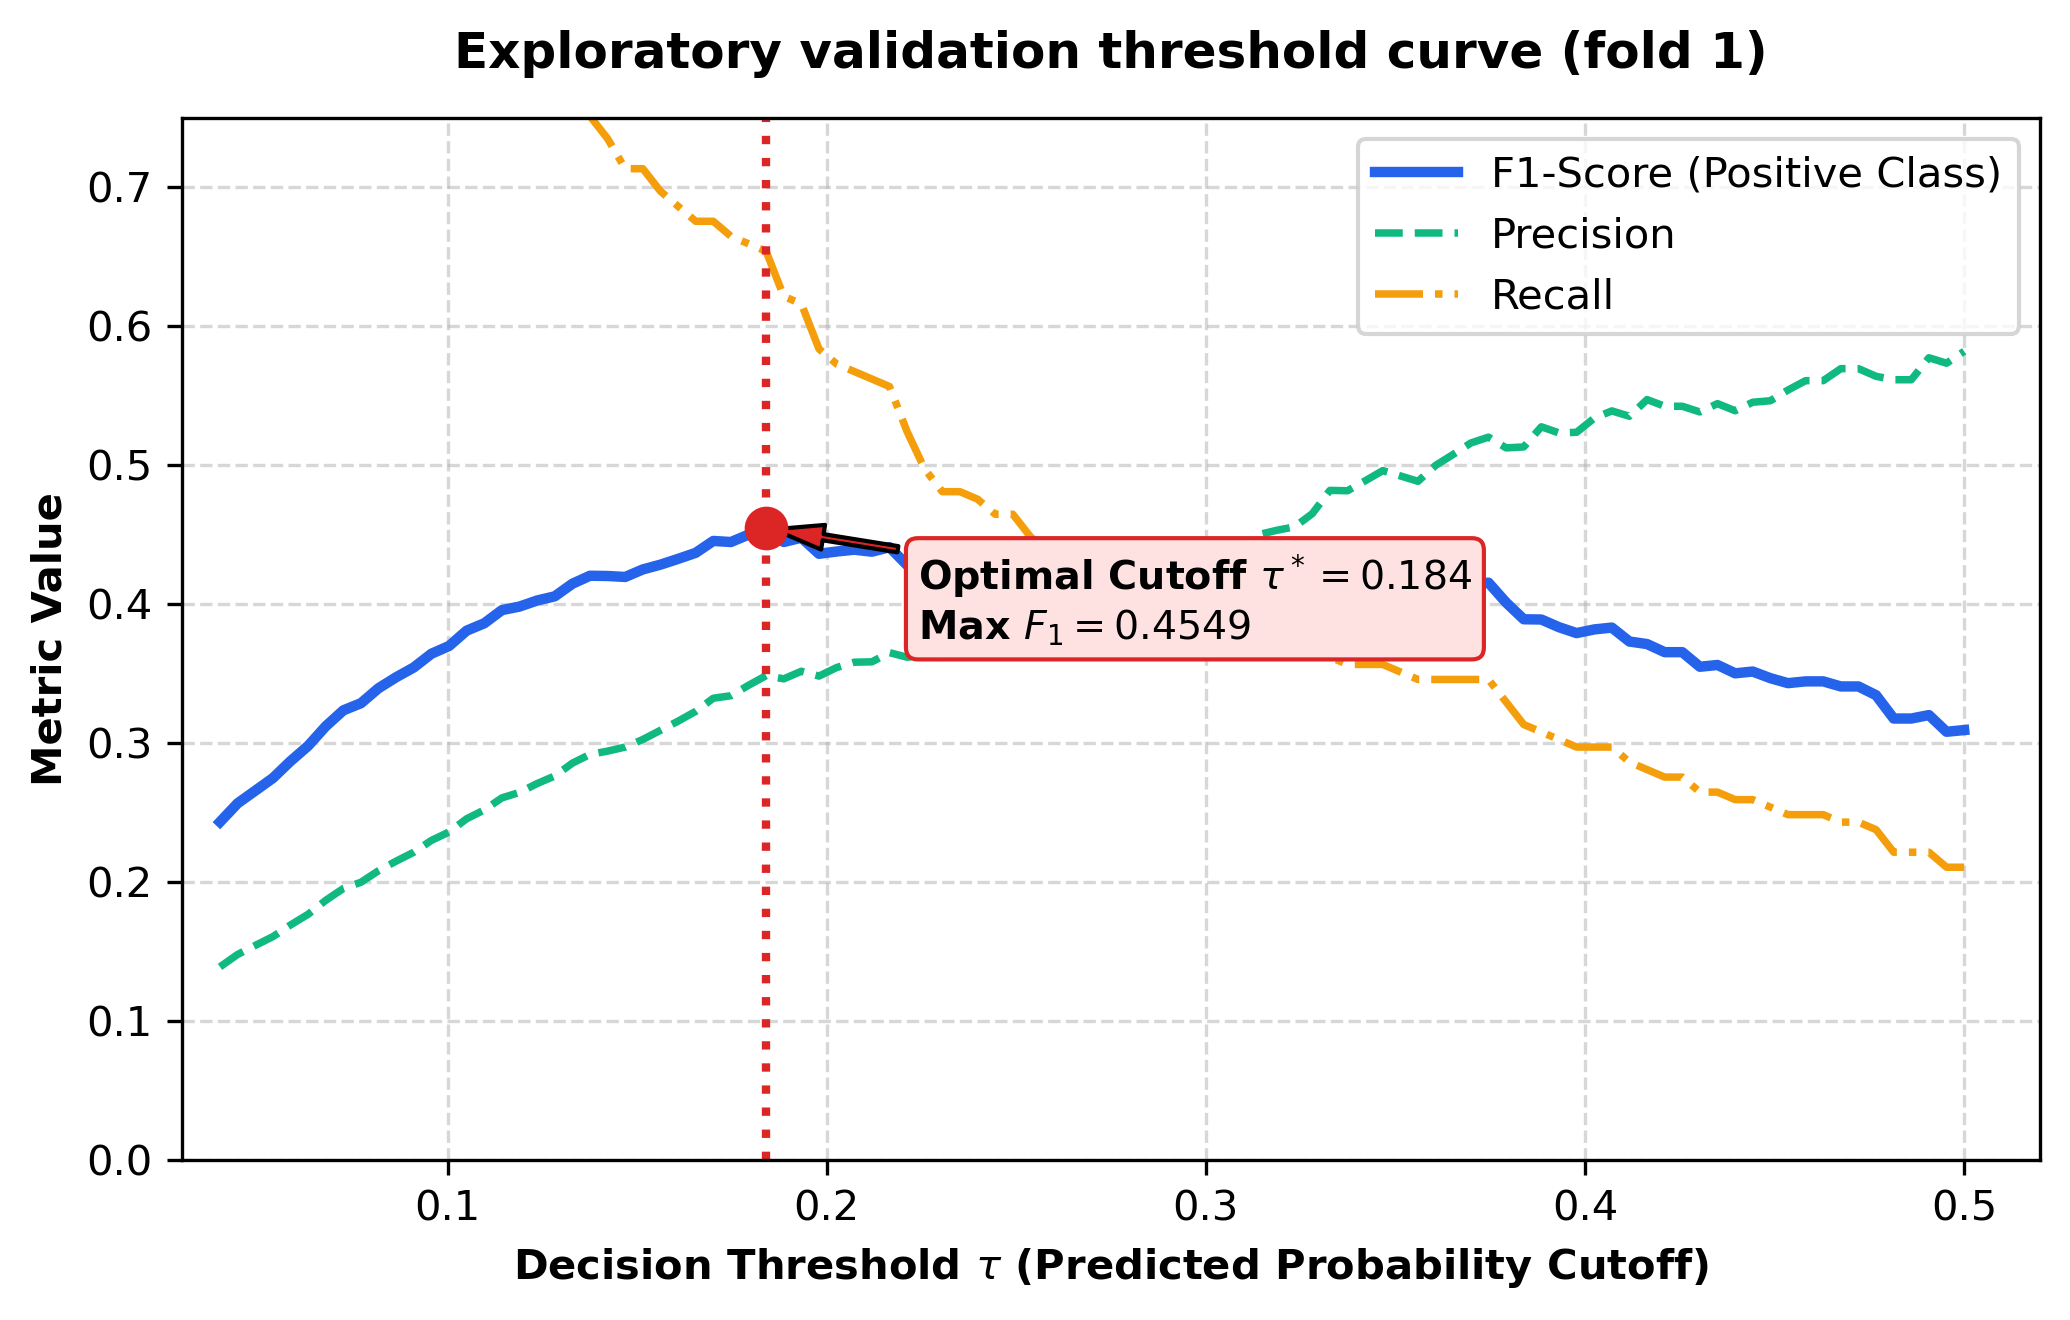

Saved fig4_threshold_vs_f1.png


In [7]:
candidates = np.linspace(0.04, 0.50, 100)
pos_s = np.sort(probs_val[y_val_f0 == 1])
neg_s = np.sort(probs_val[y_val_f0 == -1])
tp = len(pos_s) - np.searchsorted(pos_s, candidates)
fp = len(neg_s) - np.searchsorted(neg_s, candidates)
prec = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
rec = tp / len(pos_s)
f1 = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0.0)

best_idx = np.argmax(f1)
best_tau = candidates[best_idx]
best_f1 = f1[best_idx]
default_f1 = f1[np.argmin(np.abs(candidates - 0.5))]

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)
ax.plot(candidates, f1, color="#2563eb", linewidth=2.5, label="F1-Score (Positive Class)")
ax.plot(candidates, prec, color="#10b981", linestyle="--", linewidth=1.8, label="Precision")
ax.plot(candidates, rec, color="#f59e0b", linestyle="-.", linewidth=1.8, label="Recall")
ax.axvline(best_tau, color="#dc2626", linestyle=":", linewidth=2.0)
ax.scatter([best_tau], [best_f1], color="#dc2626", s=90, zorder=5)
ax.annotate(f"Optimal Cutoff $\\tau^* = {best_tau:.3f}$\nMax $F_1 = {best_f1:.4f}$", xy=(best_tau, best_f1), xytext=(best_tau + 0.04, best_f1 - 0.08), arrowprops=dict(facecolor="#dc2626", shrink=0.05, width=1.5, headwidth=6), fontweight="bold", fontsize=9.5, bbox=dict(boxstyle="round,pad=0.3", facecolor="#fee2e2", edgecolor="#dc2626"))
ax.set_xlabel("Decision Threshold $\\tau$ (Predicted Probability Cutoff)", fontweight="bold")
ax.set_ylabel("Metric Value", fontweight="bold")
ax.set_title("Exploratory validation threshold curve (fold 1)", fontweight="bold", pad=12)
ax.set_xlim(0.03, 0.52)
ax.set_ylim(0.0, 0.75)
ax.legend(loc="upper right")
ax.grid(linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../report/figures/fig4_threshold_vs_f1.png", dpi=300)
plt.show()
print("Saved fig4_threshold_vs_f1.png")

## 5. Out-of-fold confusion matrix
Aggregate predictions from all held-out folds for the logistic model whose
threshold was selected on each training fold. No fixed historical counts are used.


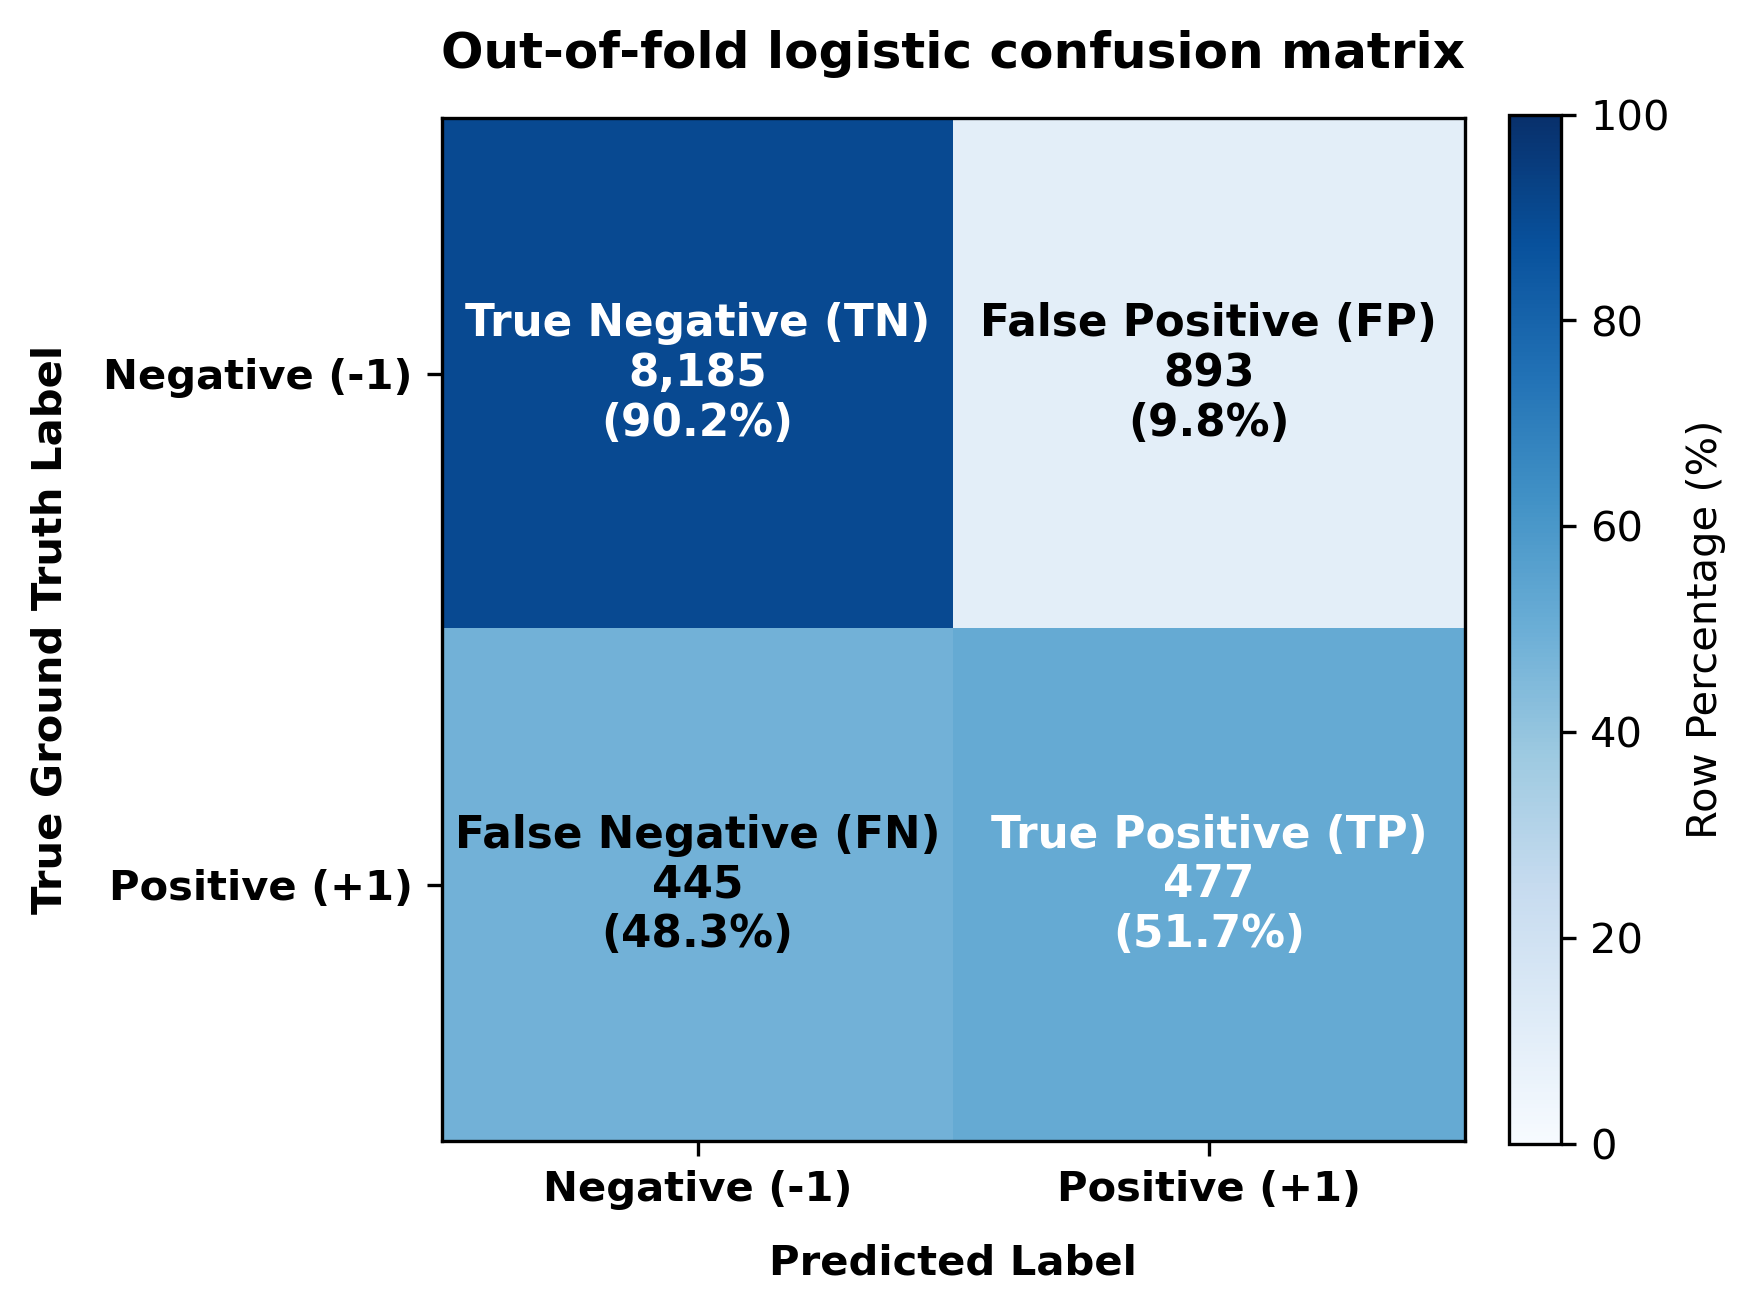

Saved fig5_confusion_matrix.png


In [8]:
# Plot and save Figure 5: Normalized Confusion Matrix
pred = oof["logistic_tuned"] == 1
truth = y_train == 1
cm = np.array([[np.sum(~truth & ~pred), np.sum(~truth & pred)],
               [np.sum(truth & ~pred), np.sum(truth & pred)]])
cm_norm = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=300)
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=100)
classes = ["Negative (-1)", "Positive (+1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes, fontweight="bold")
ax.set_yticklabels(classes, fontweight="bold")
ax.set_xlabel("Predicted Label", fontweight="bold", labelpad=8)
ax.set_ylabel("True Ground Truth Label", fontweight="bold", labelpad=8)
ax.set_title("Out-of-fold logistic confusion matrix", fontweight="bold", pad=12)

cell_labels = [["True Negative (TN)", "False Positive (FP)"], ["False Negative (FN)", "True Positive (TP)"]]
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = cm_norm[i, j]
        color = "white" if pct > 50 else "black"
        ax.text(j, i, f"{cell_labels[i][j]}\n{val:,}\n({pct:.1f}%)", ha="center", va="center", color=color, fontsize=10.5, fontweight="bold")

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Row Percentage (%)")
plt.tight_layout()
plt.savefig("../report/figures/fig5_confusion_matrix.png", dpi=300)
plt.show()
print("Saved fig5_confusion_matrix.png")

## 6. Save measured results for the report
The table above is computed by this run. The JSON below includes sample size,
seed and model budget so reduced-data results cannot be mistaken for full CV.


In [9]:
import json
result_path = ROOT / "experiments/results/notebook_baselines.json"
result_path.parent.mkdir(parents=True, exist_ok=True)
result_path.write_text(json.dumps(dict(n_rows=len(y_train), seed=SEED,
    k_folds=K_FOLDS, max_iters=MAX_ITERS,
    results={name: summarize_rows(rows) for name, rows in records.items()}), indent=2))
print("Saved", result_path)


Saved /Users/chenguanyu/Desktop/Machine Learning/proj.1/ML_Project1-zhihao 4/experiments/results/notebook_baselines.json


## 7. Final Configuration & Verification
We verify that `run.py` uses the optimal parameters and produces the submission CSV.

In [10]:
sub_path = "../submissions/submission_baseline_logistic.csv"
if os.path.exists(sub_path):
    with open(sub_path) as f:
        n_lines = sum(1 for _ in f)
    print(f"Verified submission file: {sub_path}")
    print(f"Total lines: {n_lines} (1 header + 109,379 predictions)")
else:
    print("Open PIPELINE_WORKFLOW.ipynb and run its submission-training cell.")

Open PIPELINE_WORKFLOW.ipynb and run its submission-training cell.
